# CellProfiler Single-cell Feature Extraction

We extract the QC-pass CellProfiler feature per each single cell and clean up the features.

In [53]:
import os
import random
import operator
from tqdm import tqdm
import polars as pl
import seaborn as sns
from adjustText import adjust_text
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from functools import reduce
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics.pairwise import cosine_distances
import networkx as nx
import community.community_louvain as community_louvain
import umap
from pycytominer.feature_select import feature_select

import sys
sys.path.append("../../../../1_allele_collection/2_analysis")
from plot_utils import *
sys.path.append("../1_snakemake_pipeline/2025_varchamp_snakemake")
from img_utils import *
sys.path.append("../../..")
from analyses_plot_utils import *
from utils import *

sns.set_style(style='white')
sns.set_context("notebook", font_scale=.9)

# controls = {
#     "TC": ["EGFP"],
#     "NC": ["RHEB", "MAPK9", "PRKACB", "SLIRP"],
#     "PC": ["ALK", "ALK_Arg1275Gln", "PTK2B"],
#     # "cPC": ["KRAS", "PTK2B", "GHSR", "ABL1", "BRD4", 
#     # "OPRM1", "RB1", "ADA", "WT PMP22", "LYN", "TNF", 
#     # "CYP2A6", "CSK", "PAK1", "ALDH2", "CHRM3", "KCNQ2", 
#     # "ALK T1151M", "PRKCE", "LPAR1", "PLP1"]
# }
# ctrl_alleles = [k_v for k_v in controls.values()]
# ctrl_alleles_flat = [allele for sublist in ctrl_alleles for allele in sublist]
# # ctrl_alleles_flat

## classification results in SM pipeline
SM_CLASS_RES_DIR = CLASS_RESULTS_DIR + "/{batch_id}/profiles_tcdropped_filtered_var_mad_outlier_featselect_filtcells"
FEAT = "GFP"
MISLOCALIZED_LABEL = "Altered_95th_perc_both_batches_GFP"

## QC-ed PQ files
ALL_PROF_QC = PROF_DIR + "/{batch_id}/profiles_tcdropped_filtered_var_mad_outlier.parquet"
PASS_QC_PROF_PQ = PROF_DIR + "/{batch_id}/profiles_tcdropped_filtered_var_mad_outlier_featselect_filtcells.parquet"

np.random.seed(42)
random.seed(42)

In [3]:
imaging_summary_clinvar = pl.read_csv("../../3_outputs/imaging_analyses_summary_clinvar.tsv", separator="\t", infer_schema_length=10000000)
imaging_summary_clinvar_hits = imaging_summary_clinvar.filter(
    pl.col(MISLOCALIZED_LABEL)==1
)
print("Number of hits:", imaging_summary_clinvar_hits.shape[0])
allele_list = list(imaging_summary_clinvar["gene_allele"]) + list(imaging_summary_clinvar["Gene"].unique())
hits_allele_list = list(imaging_summary_clinvar_hits["gene_allele"]) + list(imaging_summary_clinvar_hits["Gene"].unique())
bio_reps = list(imaging_summary_clinvar_hits["Metadata_Bio_Batch"].unique())
imaging_summary_clinvar.shape

Number of hits: 178


## 1. Load classifier info, feature importance and CellProfiler features

In [2]:
allele_meta_df = pl.DataFrame()
allele_meta_df_dict, img_well_qc_sum_dict = {}, {}

for bio_rep, bio_rep_batches in BIO_REP_BATCHES_DICT.items():
    for batch_id in bio_rep_batches:
        allele_meta_df_batch = pl.DataFrame()
        platemaps = [file for file in os.listdir(PLATEMAP_DIR.format(batch_id=batch_id)) if file.endswith(".txt")]
        for platemap in platemaps:
            platemap_df = pl.read_csv(os.path.join(PLATEMAP_DIR.format(batch_id=batch_id), platemap), separator="\t", infer_schema_length=100000)
            allele_meta_df_batch = pl.concat([allele_meta_df_batch, 
                                        platemap_df.filter((pl.col("node_type").is_not_null()))], # (~pl.col("node_type").is_in(["TC","NC","PC"]))&
                                        how="diagonal_relaxed").sort("plate_map_name")
            allele_meta_df_batch = allele_meta_df_batch.with_columns(pl.col("plate_map_name").alias("plate_map")) ## str.split('_').list.get(0).
            # display(allele_meta_df.head())
        allele_meta_df = pl.concat([
            allele_meta_df,
            allele_meta_df_batch
        ], how="diagonal_relaxed")#.sort("plate_map_name") ## (~pl.col("node_type").is_in(["TC","NC","PC"]))&
    allele_meta_df_dict[bio_rep] = allele_meta_df_batch

    img_well_qc_sum = pl.read_csv(f"{IMGS_QC_METRICS_DIR}/{bio_rep}/plate-well-level_img_qc_sum.csv")
    img_well_qc_sum = img_well_qc_sum.with_columns(
        pl.col("channel").replace("DAPI", "DNA").alias("channel")
    )
    img_well_qc_sum_morph = img_well_qc_sum.filter(pl.col("channel")!="GFP")
    img_well_qc_sum_morph = img_well_qc_sum_morph.group_by(["plate","well"]).agg(
        pl.col("is_bg").max().alias("is_bg"),
        pl.col("s2n_ratio").mean().alias("s2n_ratio")
    ).with_columns(pl.lit("Morph").alias("channel"))
    img_well_qc_sum = pl.concat([
        img_well_qc_sum.select(pl.col(["plate","well","channel","is_bg","s2n_ratio"])),
        img_well_qc_sum_morph.select(pl.col(["plate","well","channel","is_bg","s2n_ratio"])),
    ], how="vertical_relaxed")
    img_well_qc_sum_dict[bio_rep] = img_well_qc_sum

### 1.1 Load classifier info

#### 1.1.1 Load feature importance for each variant

In [7]:
# feat_import_df_feat = pl.DataFrame()
# for bio_rep in bio_reps:
#     bio_rep_batches = BIO_REP_BATCHES_DICT[bio_rep]
#     ## ONLY grep the allele come from the bio-rep
#     allele_batch_df = imaging_summary_clinvar.filter(pl.col("Metadata_Bio_Batch")==bio_rep)
#     batch_allele_list = list(allele_batch_df["gene_allele"]) + list(allele_batch_df["Gene"].unique())
#     for batch_id in bio_rep_batches:
#         # Read the data
#         feat_df = pl.scan_csv(f"{SM_CLASS_RES_DIR.format(batch_id=batch_id)}/feat_importance.csv")
#         meta_cols = [c for c in feat_df.collect_schema().names() if c.startswith("Metadata_") or c.startswith("Group") or c == "Batch"]
#         feat_cols = [c for c in feat_df.collect_schema().names() if c not in meta_cols and FEAT in c]
#         feat_df_batch = feat_df.with_columns(
#             [pl.col(c).cast(pl.Float64, strict=False).alias(c) for c in feat_cols]
#         ).with_columns(
#             pl.lit(batch_id).alias("Metadata_Batch"),
#             pl.col("Group2").str.split('_').list.slice(-2).list.join("_").alias("Metadata_gene_allele")
#        ).filter(
#             (pl.col("Metadata_Feature_Type")==FEAT)&(~pl.col("Metadata_Control"))
#             &(pl.col("Group1").is_in(allele_list)|(pl.col("Metadata_gene_allele").is_in(batch_allele_list)))
#         ).select(meta_cols + feat_cols + ["Metadata_Batch", "Metadata_gene_allele"])
#         feat_import_df_feat = pl.concat([feat_import_df_feat, feat_df_batch.collect()], how="diagonal")

In [8]:
# key_alleles_df = imaging_summary_clinvar.to_pandas()
# feat_df = pl.DataFrame()
# importance_thres = 1e-3
# # top_num = 5

# for j, allele in tqdm(key_alleles_df.iterrows()):
#     batch_list = list(feat_import_df_feat.filter(
#         pl.col("Metadata_gene_allele")==allele["gene_allele"]
#     ).unique("Metadata_Batch")["Metadata_Batch"])
#     allele_df = pl.DataFrame()
#     for i, batch in enumerate(batch_list):
#         batch_df = feat_import_df_feat.filter(
#             (pl.col("Metadata_Batch")==batch)&(pl.col("Metadata_gene_allele")==allele["gene_allele"])
#         )
#         feat_cols = [col for col in batch_df.columns if "Metadata" not in col and "Group" not in col]
#         batch_df = batch_df.filter(
#             ~pl.all_horizontal(pl.col(feat_cols).is_null())
#         )
#         non_null_gfp = [col for col in feat_cols if not batch_df[col].is_null().any()]
#         batch_df_col = (
#             batch_df.select(non_null_gfp).mean()
#            .transpose(include_header=True)
#            .filter(pl.col("column_0") > importance_thres)
#            .sort("column_0", descending=True)
#            # .head(top_num)#["column"]
#            # .to_list()
#         )
#         if not allele_df.is_empty():
#             allele_df = allele_df.join(
#                 batch_df_col.with_columns(
#                     pl.col("column_0").alias(batch),
#                     pl.col("column").alias("index"),
#                 ).select("index", batch),
#                 on="index",
#                 how="full",
#                 coalesce=True
#             )
#         else:
#             allele_df = batch_df_col.with_columns(
#                 pl.col("column_0").alias(batch),
#                 pl.col("column").alias("index"),
#             ).select("index", batch)
            
#     allele_df = allele_df.with_columns(
#         pl.mean_horizontal(pl.col([col for col in allele_df.columns if "Batch" in col])).alias("feat_importance"),
#         pl.col("index").alias("cp_feature")
#     ).select(
#         pl.col(["cp_feature", "feat_importance"])
#     ).rename(
#         {"feat_importance": allele["gene_allele"]}
#     )
#     if not feat_df.is_empty():
#         feat_df = feat_df.join(
#             allele_df,
#             left_on="cp_feature",
#             right_on="cp_feature",
#             how="full",
#             coalesce=True
#         )
#     else:
#         feat_df = allele_df

888it [02:39,  5.57it/s]


#### 1.1.2 Output significant features contribute to distinguish mislocalized variants

In [9]:
# feat_df.write_csv("../../3_outputs/feat_importance_gt1e-3_all_alleles.csv")

### 1.2 Load CellProfiler features

#### 1.2.1 Load the features from the valid cells only

In [16]:
# # Paths
# ref_var_cell_qc_prof_df = pl.DataFrame()
# target_gene_alleles = []
# meta_cols = [
#     "Metadata_CellID",
#     "Metadata_gene_allele",
#     "Metadata_Well",
#     "Metadata_Plate",
#     "Metadata_node_type"
# ]
# # Get meta features
# for bio_rep in bio_reps:
#     bio_rep_batches = BIO_REP_BATCHES_DICT[bio_rep]
#     ## ONLY grep the allele come from the bio-rep
#     allele_batch_df = imaging_summary_clinvar.filter(pl.col("Metadata_Bio_Batch")==bio_rep)
#     batch_allele_list = list(allele_batch_df["gene_allele"]) + list(allele_batch_df["Gene"].unique())
#     for batch_id in bio_rep_batches:
#         batch_alleles = (
#             pl.scan_parquet(
#                 PASS_QC_PROF_PQ.format(batch_id=batch_id)
#             )
#             .filter(pl.col("Metadata_gene_allele").is_in(batch_allele_list))
#             .with_columns(
#                 pl.concat_str(
#                     [
#                         "Metadata_Plate",
#                         "Metadata_Well",
#                         "Metadata_ImageNumber",
#                         "Metadata_ObjectNumber",
#                     ],
#                     separator="_",
#                 ).alias("Metadata_CellID")
#             )
#         ).collect()
#         # feat_cols = [col for col in batch_alleles.columns if ("AGP".lower() in col.lower() or "DNA".lower() in col.lower() or "Mito".lower() in col.lower()) and ("GFP".lower() not in col.lower())]
#         batch_alleles = batch_alleles.join(
#             img_well_qc_sum_dict[bio_rep].filter(pl.col("channel")==FEAT).select(pl.col("plate", "well", "is_bg")),
#             left_on=["Metadata_Plate", "Metadata_Well"],
#             right_on=["plate", "well"]
#         ).filter(
#             ~pl.col("is_bg")
#         ).select(pl.col(meta_cols))
#         ref_var_cell_qc_prof_df = pl.concat([ref_var_cell_qc_prof_df, batch_alleles], how="diagonal_relaxed")

#### 1.2.2 Load all the features available

In [17]:
# # Paths
# ref_var_cell_all_prof_list = []
# for bio_rep, bio_rep_batches in BIO_REP_BATCHES_DICT.items():
#     ## ONLY grep the allele come from the bio-rep
#     allele_batch_df = imaging_summary_clinvar.filter(pl.col("Metadata_Bio_Batch")==bio_rep)
#     batch_allele_list = list(allele_batch_df["gene_allele"]) + list(allele_batch_df["Gene"].unique())
#     for batch_id in bio_rep_batches:
#         batch_alleles = (
#             pl.scan_parquet(
#                 ALL_PROF_QC.format(batch_id=batch_id)
#             )
#             .filter(pl.col("Metadata_gene_allele").is_in(batch_allele_list))
#             .with_columns(
#                 pl.concat_str(
#                     [
#                         "Metadata_Plate",
#                         "Metadata_Well",
#                         "Metadata_ImageNumber",
#                         "Metadata_ObjectNumber",
#                     ],
#                     separator="_",
#                 ).alias("Metadata_CellID")
#             )
#         )
#         ref_var_cell_all_prof_list.append(batch_alleles)

# all_feat_cols = reduce(
#     set.intersection, 
#     map(set, [[col for col in ref_var_cell_all_prof.collect_schema() \
#                if (FEAT.lower() in col.lower()) and ("Brightfield".lower() not in col.lower())] 
#                for ref_var_cell_all_prof in ref_var_cell_all_prof_list])
# )

# select_cols = list(all_feat_cols) + ["Metadata_CellID"]
# ref_var_cell_all_prof_df = pl.concat([
#     batch_alleles.select(select_cols).collect() for batch_alleles in ref_var_cell_all_prof_list
# ])

# # This method of joining ensures that only cells past filters are included in the abundance analysis
# ref_var_cell_all_prof_df = ref_var_cell_qc_prof_df.join(ref_var_cell_all_prof_df, 
#                                                         on="Metadata_CellID", 
#                                                         how="left", coalesce=True)

In [12]:
# ref_var_cell_all_prof_df.write_parquet("../1_snakemake_pipeline/2025_varchamp_snakemake/2.snakemake_pipeline/outputs/ref_var_gfp_feat_sc_cp_profiles_oneperc.parquet")
ref_var_cell_all_prof_df.shape

(2614654, 449)

## 2. Single-cell CP profile preprocessing

In [54]:
ref_var_cell_all_prof_df = pl.read_parquet("../1_snakemake_pipeline/2025_varchamp_snakemake/2.snakemake_pipeline/outputs/ref_var_gfp_feat_sc_cp_profiles_oneperc.parquet")
ref_var_cell_all_prof_df.shape

(2614654, 449)

### 2.1 INT Normalization

In [55]:
# Extract features once
feature_cols = [c for c in ref_var_cell_all_prof_df.columns if "Metadata" not in c]
# features = ref_var_cell_all_prof_df.select(pl.col(feature_cols))

# Standardize by INT and fit PCA
data_scaled = inverse_normal_transform(ref_var_cell_all_prof_df, feature_cols)

  0%|          | 0/444 [00:00<?, ?it/s]

### 2.2 Feature selection

In [57]:
data_scaled = feature_select(data_scaled.to_pandas(), operation="variance_threshold")
data_scaled = feature_select(data_scaled, operation="correlation_threshold")
data_scaled.shape

(2614654, 146)

### 2.3 Output Single-cell INT and Selected Features

In [59]:
# data_scaled_pl = pl.DataFrame(data_scaled)
# data_scaled_pl.write_parquet(
#     "../1_snakemake_pipeline/2025_varchamp_snakemake/2.snakemake_pipeline/outputs/ref_var_gfp_feat_sc_cp_profiles_oneperc_int_featselect.parquet"
# )

### 2.4 Aggregate to allele level

In [73]:
# feature_cols = [c for c in data_scaled_pl.columns if "Metadata" not in c]

# gene_allele_feat_df = data_scaled_pl.group_by(
#     "Metadata_gene_allele", "Metadata_Plate", "Metadata_Well"
# ).agg(
#     pl.col(col).mean().alias(col)
#     for col in feature_cols
# ).group_by(
#     "Metadata_gene_allele" ## aggregate by allele
# ).agg(
#     pl.col(col).median().alias(col)
#     for col in feature_cols
# )

In [66]:
# Standardize by INT and fit PCA
# data_scaled = inverse_normal_transform(gene_allele_feat_df, feature_cols)
# data_scaled = feature_select(data_scaled.to_pandas(), operation="variance_threshold")
# data_scaled = feature_select(data_scaled, operation="correlation_threshold")

# data_scaled.to_parquet(
#     "../1_snakemake_pipeline/2025_varchamp_snakemake/2.snakemake_pipeline/outputs/ref_var_gfp_feat_var_cp_profiles_oneperc_int_featselect.parquet"
# )

  0%|          | 0/141 [00:00<?, ?it/s]

(1007, 71)

## 3. Data Exploration

In [75]:
gene_loc_all_df = pl.read_csv("../../1_inputs/subcell_loc/subcell_loc_hpa_opencell.tsv", separator="\t")
ref_var_cell_prof_df = pl.read_parquet("../1_snakemake_pipeline/2025_varchamp_snakemake/2.snakemake_pipeline/outputs/ref_var_gfp_feat_sc_cp_profiles_oneperc_int_featselect.parquet")
ref_var_allele_prof_df = pl.read_parquet("../1_snakemake_pipeline/2025_varchamp_snakemake/2.snakemake_pipeline/outputs/ref_var_gfp_feat_var_cp_profiles_oneperc_int_featselect.parquet")

ref_var_cell_prof_df = ref_var_cell_prof_df.join(
    gene_loc_all_df,
    left_on="Metadata_gene_allele",
    right_on="Gene name",
    how="left"
)
ref_var_cell_prof_df

ref_var_allele_prof_df = ref_var_allele_prof_df.join(
    gene_loc_all_df,
    left_on="Metadata_gene_allele",
    right_on="Gene name",
    how="left"
)
ref_var_allele_prof_df.head()

Metadata_gene_allele,Cells_Correlation_RWC_Mito_GFP,Cells_RadialDistribution_RadialCV_GFP_10of10,Cytoplasm_Intensity_LowerQuartileIntensity_GFP,Nuclei_Correlation_RWC_AGP_GFP,Cytoplasm_RadialDistribution_FracAtD_GFP_10of10,Nuclei_RadialDistribution_MeanFrac_GFP_9of10,Cells_Granularity_4_GFP,Cytoplasm_Texture_AngularSecondMoment_GFP_20_00_256,Cells_Correlation_Manders_GFP_Mito,Cytoplasm_RadialDistribution_RadialCV_GFP_1of10,Cells_RadialDistribution_MeanFrac_GFP_5of10,Cytoplasm_RadialDistribution_FracAtD_GFP_9of10,Cytoplasm_RadialDistribution_MeanFrac_GFP_10of10,Cells_Texture_InfoMeas1_GFP_5_00_256,Cells_Correlation_RWC_DNA_GFP,Nuclei_Correlation_K_Mito_GFP,Cells_Correlation_Correlation_AGP_GFP,Nuclei_Correlation_RWC_GFP_Mito,Cells_Correlation_RWC_AGP_GFP,Nuclei_RadialDistribution_FracAtD_GFP_10of10,Nuclei_Texture_Correlation_GFP_5_00_256,Nuclei_Correlation_Correlation_AGP_GFP,Cells_Texture_InfoMeas1_GFP_10_01_256,Cells_Texture_Correlation_GFP_5_00_256,Cytoplasm_RadialDistribution_MeanFrac_GFP_9of10,Cells_Intensity_MassDisplacement_GFP,Cytoplasm_Texture_Correlation_GFP_5_00_256,Nuclei_RadialDistribution_MeanFrac_GFP_8of10,Cytoplasm_Texture_InfoMeas2_GFP_10_00_256,Cytoplasm_Correlation_RWC_GFP_AGP,Cells_RadialDistribution_FracAtD_GFP_8of10,Cells_Granularity_3_GFP,Cells_RadialDistribution_MeanFrac_GFP_7of10,Cells_Correlation_Correlation_GFP_Mito,Nuclei_Correlation_Overlap_GFP_Mito,Cytoplasm_RadialDistribution_MeanFrac_GFP_3of10,…,Nuclei_Texture_SumAverage_GFP_20_00_256,Cells_RadialDistribution_FracAtD_GFP_7of10,Cells_RadialDistribution_FracAtD_GFP_10of10,Nuclei_Texture_AngularSecondMoment_GFP_10_00_256,Cells_Correlation_RWC_GFP_DNA,Cells_Correlation_Correlation_DNA_GFP,Nuclei_Granularity_1_GFP,Cells_Granularity_7_GFP,Nuclei_Correlation_RWC_Mito_GFP,Cells_Texture_Correlation_GFP_20_01_256,Cells_Texture_InfoMeas2_GFP_10_02_256,Cells_Correlation_RWC_GFP_Mito,Cytoplasm_Correlation_Correlation_DNA_GFP,Cytoplasm_RadialDistribution_MeanFrac_GFP_8of10,Nuclei_RadialDistribution_RadialCV_GFP_1of10,Nuclei_Texture_Correlation_GFP_20_02_256,Cells_RadialDistribution_FracAtD_GFP_9of10,Cytoplasm_RadialDistribution_FracAtD_GFP_8of10,Cytoplasm_RadialDistribution_FracAtD_GFP_7of10,Cytoplasm_Granularity_2_GFP,Cells_RadialDistribution_FracAtD_GFP_1of10,Cytoplasm_Intensity_MaxIntensity_GFP,Cells_Granularity_5_GFP,Nuclei_Texture_Correlation_GFP_10_00_256,Cells_Location_MaxIntensity_X_GFP,Cytoplasm_Texture_Correlation_GFP_20_01_256,Cytoplasm_Correlation_RWC_GFP_DNA,Nuclei_Correlation_Correlation_GFP_Mito,Cytoplasm_Location_CenterMassIntensity_Y_GFP,Nuclei_Correlation_RWC_DNA_GFP,Nuclei_Granularity_4_GFP,Nuclei_Correlation_RWC_GFP_AGP,Metadata_Gene_ENSGID,Metadata_hpa_main_loc,Metadata_hpa_additional_loc,Metadata_GO_ID,Metadata_merged_approved_Loc
str,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,…,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,str,str,str,str,str
"""SMAD3_Ser355Leu""",0.914155,0.017421,0.55477,0.127261,1.265316,-1.623454,0.976401,-0.197882,-0.436537,-2.18295,1.123194,-1.176204,0.503244,-1.846771,0.952626,0.65644,-0.851682,-2.131953,0.525972,-1.340923,0.876991,-1.505129,-1.398127,1.528719,-0.650278,0.256625,0.112221,1.431989,0.13228,-0.350469,-0.345182,0.282432,1.232742,-0.74226,-0.409322,0.458543,…,0.41474,0.880653,-0.58699,-0.494788,0.560585,1.505129,-1.248863,1.095566,-0.149874,-1.623454,0.980417,-0.213132,1.553192,-0.745542,-1.713492,-2.272064,-0.540315,-1.474923,-1.038405,-1.446005,1.11853,-0.241223,1.156551,-0.195345,0.279843,0.042319,1.299289,-1.587344,0.097208,1.671797,1.453121,-1.310954,null,null,null,null,null
"""GSS_Arg125Cys""",-0.054776,0.641082,0.848111,0.079719,0.675076,-0.298006,-0.703479,-2.18295,-0.503244,-0.369054,-0.014932,-0.634981,-0.180148,0.059762,-0.089709,0.952626,1.385021,0.017421,-0.119738,-0.762073,1.017302,-0.334635,-0.68134,1.05998,

In [ ]:
ref_var_allele_prof_df.write_csv("../../3_outputs/ref_var_allele_int_featsel_cp_feat_w_loc.csv")
ref_var_cell_prof_df.write_csv("../../3_outputs/ref_var_sc_int_featsel_cp_feat_w_loc.csv")

### 3.1 Variant-level analyses

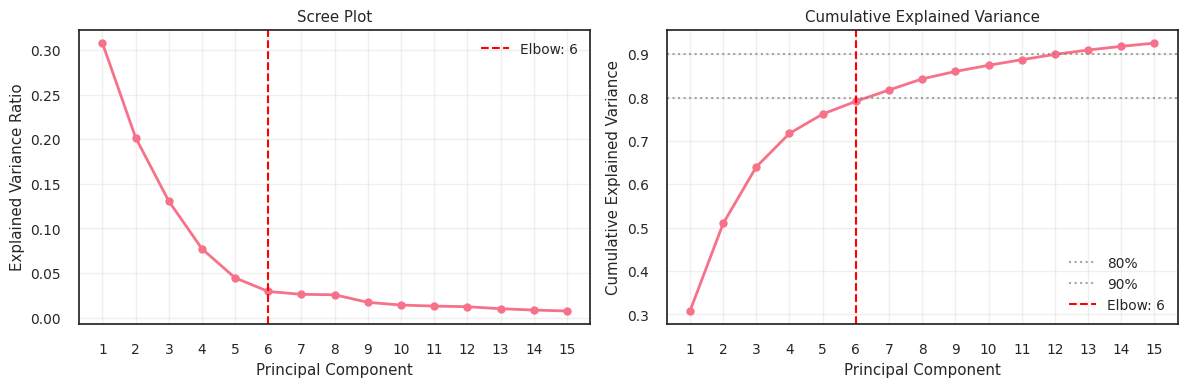

Optimal components: 6
Explained variance at elbow: 79.2%


In [71]:
pca = PCA()  # Get top 10 PCs
pca_components = pca.fit_transform(ref_var_allele_prof_df.select(
    [c for c in ref_var_allele_prof_df.columns if "Metadata_" not in c]
).to_numpy())

# Calculate variances
explained_variance_ratio = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance_ratio)

from kneed import KneeLocator
# Find elbow point using KneeLocator
knee_locator = KneeLocator(
    range(1, len(explained_variance_ratio)+1),
    explained_variance_ratio,
    curve='convex',
    direction='decreasing'
)
optimal_components = knee_locator.knee


# Plot results
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
# Scree plot
n_show = min(15, len(explained_variance_ratio))
ax1.plot(range(1, n_show + 1), explained_variance_ratio[:n_show], 'o-', linewidth=2)
ax1.axvline(x=optimal_components, color='red', linestyle='--', label=f'Elbow: {optimal_components}')
ax1.set_xlabel('Principal Component')
ax1.set_ylabel('Explained Variance Ratio')
ax1.set_title('Scree Plot')
ax1.set_xticks(range(1, n_show + 1))
ax1.legend()
ax1.grid(True, alpha=0.3)

# Cumulative variance plot
ax2.plot(range(1, n_show + 1), cumulative_variance[:n_show], 'o-', linewidth=2)
ax2.axhline(y=0.8, color='gray', linestyle=':', alpha=0.7, label='80%')
ax2.axhline(y=0.9, color='gray', linestyle=':', alpha=0.7, label='90%')
ax2.axvline(x=optimal_components, color='red', linestyle='--', label=f'Elbow: {optimal_components}')
ax2.set_xlabel('Principal Component')
ax2.set_ylabel('Cumulative Explained Variance')
ax2.set_title('Cumulative Explained Variance')
ax2.set_xticks(range(1, n_show + 1))
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Results
print(f"Optimal components: {optimal_components}")
print(f"Explained variance at elbow: {cumulative_variance[optimal_components-1]:.1%}")

In [72]:
# Apply optimal PCA
pca = PCA(n_components=optimal_components)
pca_components = pca.fit_transform(
    ref_var_allele_prof_df.select(
    [c for c in ref_var_allele_prof_df.columns if "Metadata_" not in c]
).to_numpy())

# UMAP on top 10 PCs
umap_reducer = umap.UMAP(n_components=2, random_state=42)
umap_embedding = umap_reducer.fit_transform(pca_components)

In [78]:
## Create result dataframe
data_results = pd.DataFrame({
   'PC1': pca_components[:, 0],
   'PC2': pca_components[:, 1],
   'UMAP1': umap_embedding[:, 0],
   'UMAP2': umap_embedding[:, 1],
   'Metadata_hpa_main_loc': ref_var_allele_prof_df["Metadata_hpa_main_loc"],
   'Metadata_gene_allele': ref_var_allele_prof_df["Metadata_gene_allele"],
   'Metadata_hpa_additional_loc': ref_var_allele_prof_df["Metadata_hpa_additional_loc"],
   # "Metadata_GO_ID"	
   #  "Metadata_merged_approved_Loc"
    # 'Metadata_CellID': ref_var_allele_prof_df["Metadata_CellID"],
    # 'Metadata_Batch': ref_var_allele_prof_df["Metadata_Plate"].str.extract(r'B(\d+)A'),
})

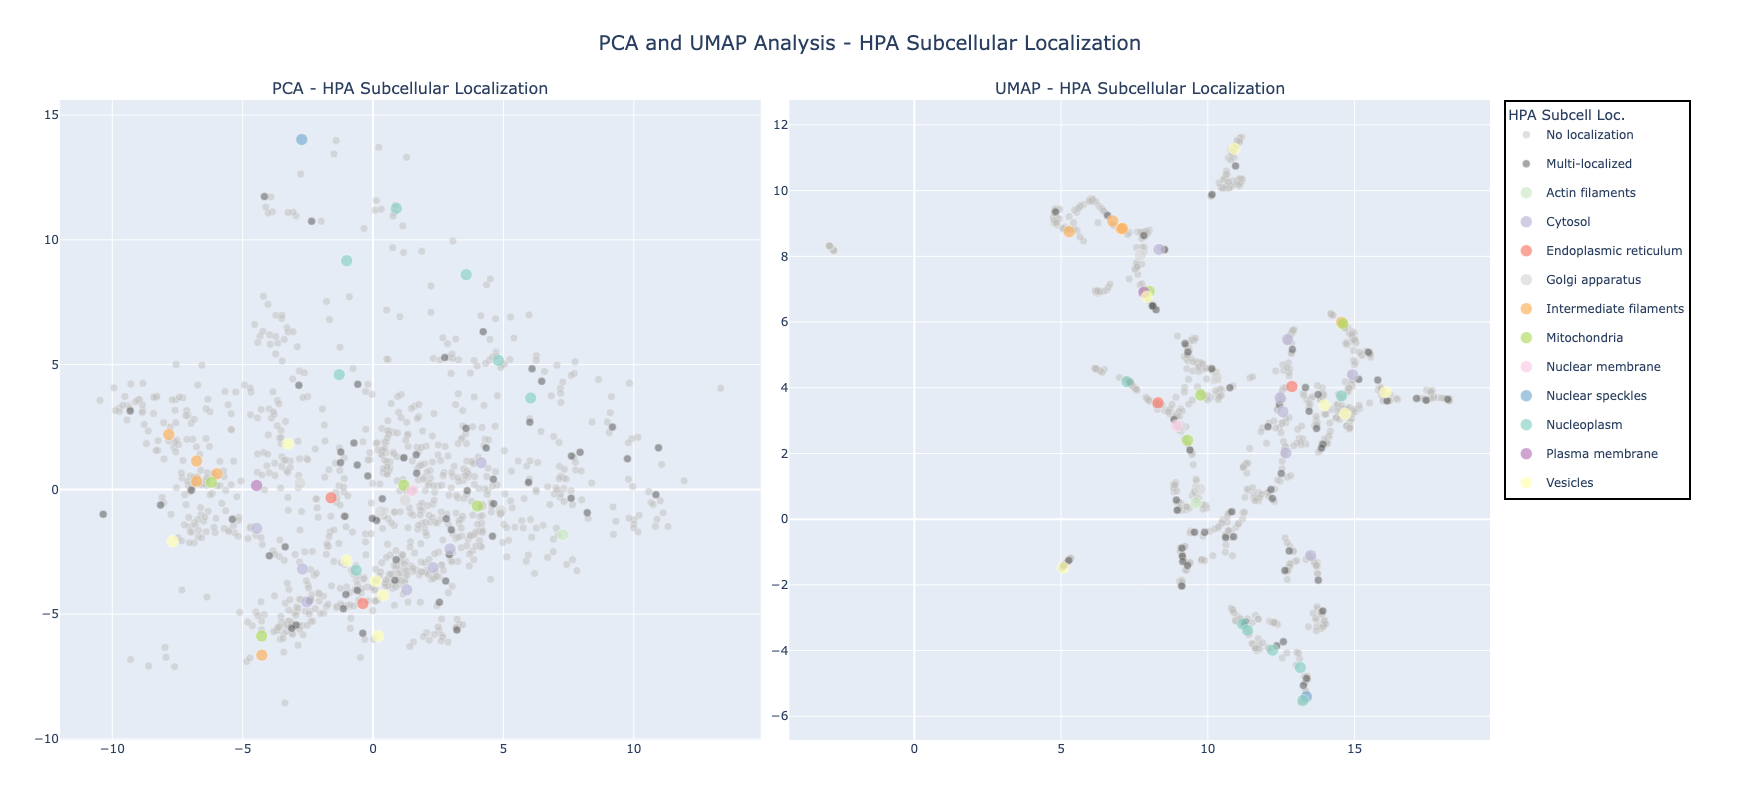


Dataset Summary:
Total genes: 1007
Localization patterns:
localization_category
No localization           909
Multi-localized            59
Nucleoplasm                 7
Cytosol                     7
Vesicles                    6
Intermediate filaments      5
Mitochondria                4
Golgi apparatus             4
Endoplasmic reticulum       2
Nuclear speckles            1
Nuclear membrane            1
Plasma membrane             1
Actin filaments             1
Name: count, dtype: int64


In [118]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

def create_localization_only_plots(df):
   """Create PCA and UMAP plots colored only by localization"""
   
   df = df.copy()
   df['localization_category'] = df.apply(lambda row: 
       'No localization' if (pd.isna(row['Metadata_hpa_main_loc']) or row['Metadata_hpa_main_loc'] == 'None') else
       'Multi-localized' if (';' in str(row['Metadata_hpa_main_loc']) or 
                            (not pd.isna(row['Metadata_hpa_additional_loc']) and 
                             row['Metadata_hpa_additional_loc'] != 'None')) else
       str(row['Metadata_hpa_main_loc']), axis=1
   )
   
   # Create subplots with reduced spacing
   fig = make_subplots(
       rows=1, cols=2,
       subplot_titles=('PCA - HPA Subcellular Localization', 'UMAP - HPA Subcellular Localization'),
       horizontal_spacing=0.02
   )
   
   # Color schemes
   unique_locs = [loc for loc in df['localization_category'].unique() 
                  if loc not in ['No localization', 'Multi-localized']]
   colors = px.colors.qualitative.Set3 + px.colors.qualitative.Pastel + px.colors.qualitative.Set1
   loc_colors = {loc: colors[i % len(colors)] for i, loc in enumerate(unique_locs)}
   loc_colors['No localization'] = '#C0C0C0'
   loc_colors['Multi-localized'] = '#505050'
   
   # Plot configurations
   plots_config = [
       ('PC1', 'PC2', 1, 1),
       ('UMAP1', 'UMAP2', 1, 2)
   ]
   
   # Define plotting order: background categories first, then specific localizations
   background_categories = ['No localization', 'Multi-localized']
   specific_categories = [cat for cat in sorted(df['localization_category'].unique()) 
                        if cat not in background_categories]
   plot_order = background_categories + specific_categories
   
   for x_col, y_col, row, col in plots_config:
       for i, value in enumerate(plot_order):
           if value not in df['localization_category'].values:
               continue
               
           subset = df[df['localization_category'] == value]
           
           if len(subset) == 0:
               continue
           
           color = loc_colors.get(value, '#000000')
           # Make background categories less prominent but still visible
           if value in ['No localization', 'Multi-localized']:
               opacity = 0.5
               size = 8
           else:
               opacity = 0.7
               size = 12
           
           # Only show legend for first subplot to avoid duplicates
           show_legend = (col == 1)
           
           fig.add_trace(
               go.Scatter(
                   x=subset[x_col],
                   y=subset[y_col],
                   mode='markers',
                   name=str(value),
                   legendgroup=str(value),
                   showlegend=show_legend,
                   marker=dict(
                       color=color, 
                       size=size, 
                       opacity=opacity,
                       line=dict(width=0.5, color='white')
                   ),
                   customdata=np.column_stack((
                       subset.index,
                       subset['Metadata_hpa_main_loc'].fillna('None')
                   )),
                   hovertemplate='<b>%{customdata[0]}</b><br>' +
                                f'{x_col}: %{{x:.3f}}<br>' +
                                f'{y_col}: %{{y:.3f}}<br>' +
                                'Localization: %{customdata[1]}<br>' +
                                '<extra></extra>'
               ),
               row=row, col=col
           )
   
   # Update subplot titles with larger font
   for i, annotation in enumerate(fig['layout']['annotations']):
       annotation['font'] = dict(size=16)
   
   fig.update_layout(
       title=dict(
           text='PCA and UMAP Analysis - HPA Subcellular Localization',
           font=dict(size=20),
           x=0.5
       ),
       height=800,
       width=1600,
       legend=dict(
           title=dict(text='HPA Subcell Loc.', font=dict(size=14)),
           font=dict(size=12),
           yanchor="top",
           y=1.0,
           xanchor="left",
           x=1.01,
           bgcolor="rgba(255,255,255,0.9)",
           bordercolor="Black",
           borderwidth=2
       ),
       margin=dict(l=60, r=250, t=100, b=60),
       showlegend=True
   )
   
   # Update axis labels
   fig.update_xaxes(title_font=dict(size=14), tickfont=dict(size=12))
   fig.update_yaxes(title_font=dict(size=14), tickfont=dict(size=12))
   
   return fig

# Usage
dashboard = create_localization_only_plots(df=data_results.set_index("Metadata_gene_allele"))
dashboard.show()

# Show summary statistics
print("\nDataset Summary:")
print(f"Total genes: {len(data_results)}")
df_indexed = data_results.set_index("Metadata_gene_allele")
df_indexed['localization_category'] = df_indexed.apply(lambda row: 
   'No localization' if (pd.isna(row['Metadata_hpa_main_loc']) or row['Metadata_hpa_main_loc'] == 'None') else
   'Multi-localized' if (';' in str(row['Metadata_hpa_main_loc']) or 
                        (not pd.isna(row['Metadata_hpa_additional_loc']) and 
                         row['Metadata_hpa_additional_loc'] != 'None')) else
   str(row['Metadata_hpa_main_loc']), axis=1
)
print(f"Localization patterns:")
print(df_indexed['localization_category'].value_counts())

### 3.2 Single Cell Level

In [121]:
ref_var_cell_prof_df.shape

(2614654, 151)

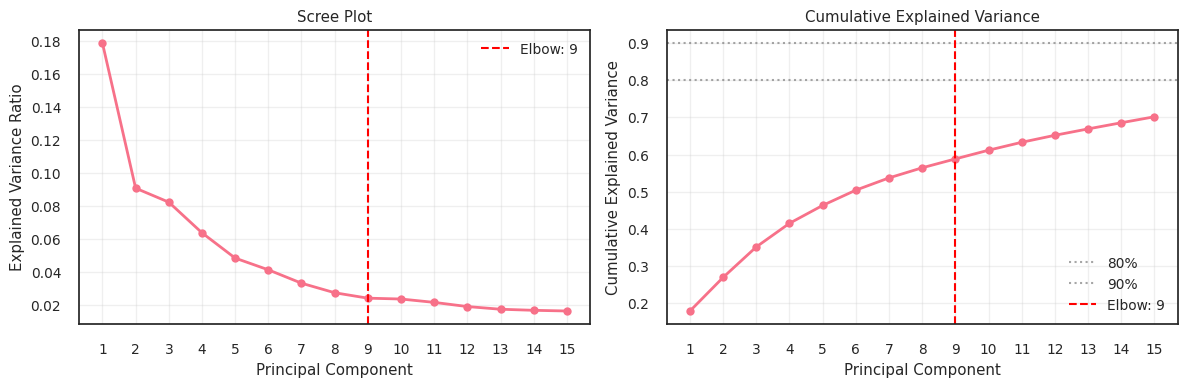

Optimal components: 9
Explained variance at elbow: 58.8%


In [122]:
pca = PCA()  # Get top 10 PCs
pca_components = pca.fit_transform(ref_var_cell_prof_df.select(
    [c for c in ref_var_allele_prof_df.columns if "Metadata_" not in c]
).to_numpy())

# Calculate variances
explained_variance_ratio = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance_ratio)

from kneed import KneeLocator
# Find elbow point using KneeLocator
knee_locator = KneeLocator(
    range(1, len(explained_variance_ratio)+1),
    explained_variance_ratio,
    curve='convex',
    direction='decreasing'
)
optimal_components = knee_locator.knee


# Plot results
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
# Scree plot
n_show = min(15, len(explained_variance_ratio))
ax1.plot(range(1, n_show + 1), explained_variance_ratio[:n_show], 'o-', linewidth=2)
ax1.axvline(x=optimal_components, color='red', linestyle='--', label=f'Elbow: {optimal_components}')
ax1.set_xlabel('Principal Component')
ax1.set_ylabel('Explained Variance Ratio')
ax1.set_title('Scree Plot')
ax1.set_xticks(range(1, n_show + 1))
ax1.legend()
ax1.grid(True, alpha=0.3)

# Cumulative variance plot
ax2.plot(range(1, n_show + 1), cumulative_variance[:n_show], 'o-', linewidth=2)
ax2.axhline(y=0.8, color='gray', linestyle=':', alpha=0.7, label='80%')
ax2.axhline(y=0.9, color='gray', linestyle=':', alpha=0.7, label='90%')
ax2.axvline(x=optimal_components, color='red', linestyle='--', label=f'Elbow: {optimal_components}')
ax2.set_xlabel('Principal Component')
ax2.set_ylabel('Cumulative Explained Variance')
ax2.set_title('Cumulative Explained Variance')
ax2.set_xticks(range(1, n_show + 1))
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Results
print(f"Optimal components: {optimal_components}")
print(f"Explained variance at elbow: {cumulative_variance[optimal_components-1]:.1%}")

In [123]:
# Apply optimal PCA
pca = PCA(n_components=optimal_components)
pca_components = pca.fit_transform(
    ref_var_cell_prof_df.select(
    [c for c in ref_var_cell_prof_df.columns if "Metadata_" not in c]
).to_numpy())

# UMAP on top 10 PCs
umap_reducer = umap.UMAP(n_components=2, random_state=42)
umap_embedding = umap_reducer.fit_transform(pca_components)

In [128]:
## Create result dataframe
data_results = pd.DataFrame({
    'PC1': pca_components[:, 0],
    'PC2': pca_components[:, 1],
    'UMAP1': umap_embedding[:, 0],
    'UMAP2': umap_embedding[:, 1],
    'Metadata_CellID': ref_var_cell_prof_df["Metadata_CellID"],
    'Metadata_Batch': ref_var_cell_prof_df["Metadata_Plate"].str.extract(r'B(\d+)A'),
    'Metadata_hpa_main_loc': ref_var_cell_prof_df["Metadata_hpa_main_loc"],
    'Metadata_gene_allele': ref_var_cell_prof_df["Metadata_gene_allele"],
    'Metadata_hpa_additional_loc': ref_var_cell_prof_df["Metadata_hpa_additional_loc"],
    'Metadata_GO_ID': ref_var_cell_prof_df["Metadata_GO_ID"],
    'Metadata_merged_approved_Loc': ref_var_cell_prof_df["Metadata_merged_approved_Loc"]
})

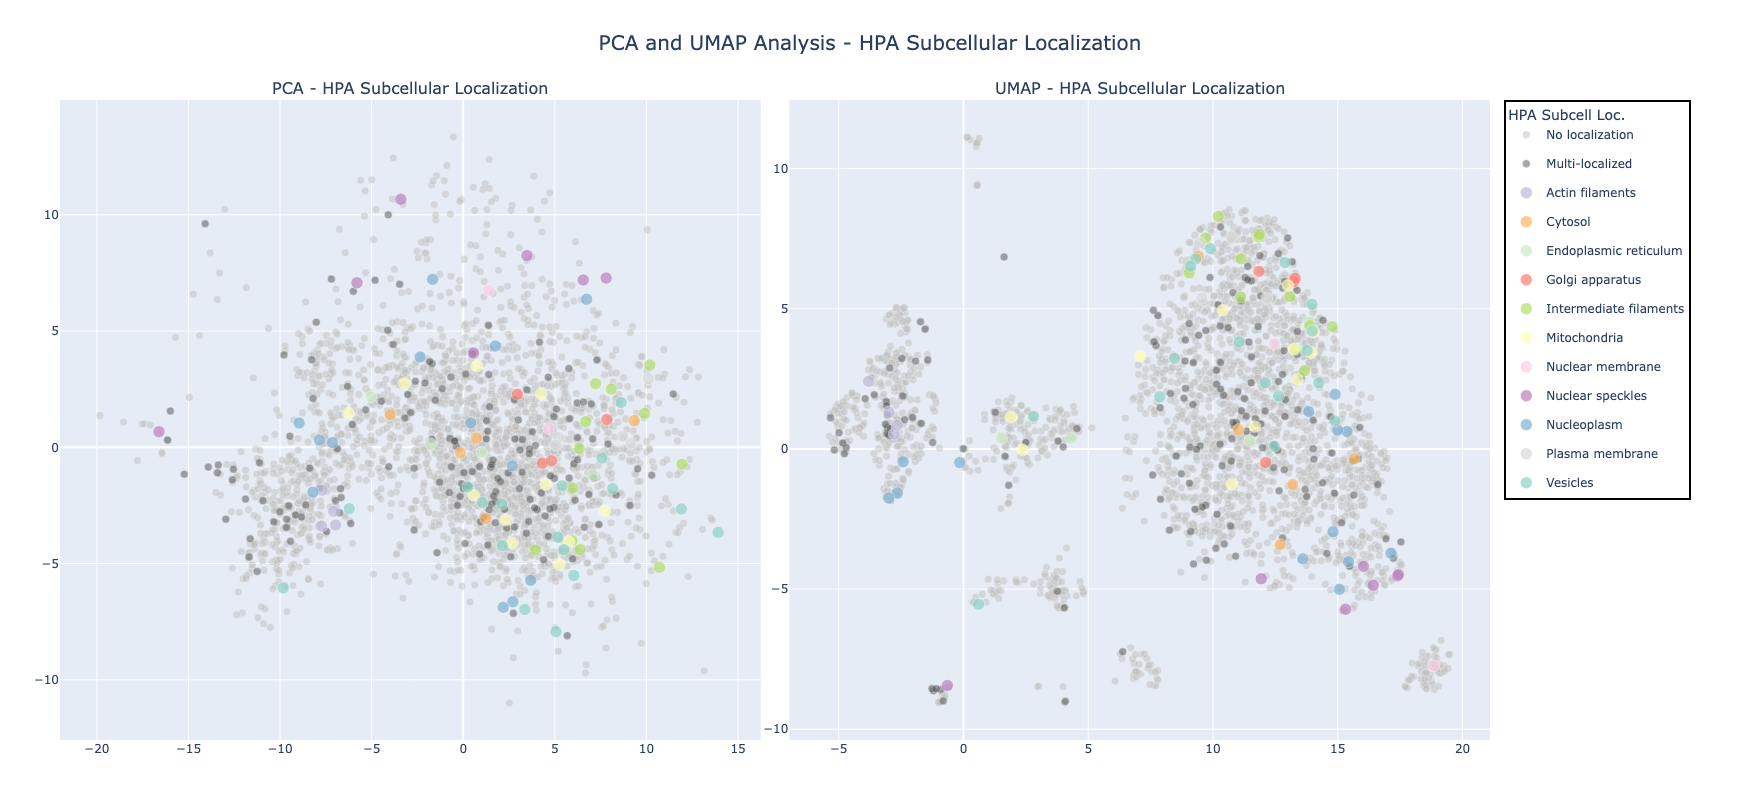


Dataset Summary:
Total genes: 2614654
Localization patterns:
localization_category
No localization           2364791
Multi-localized            166408
Vesicles                    19587
Nucleoplasm                 16131
Cytosol                     10321
Intermediate filaments       9241
Mitochondria                 7976
Golgi apparatus              5067
Plasma membrane              4990
Endoplasmic reticulum        3807
Nuclear speckles             3556
Nuclear membrane             1410
Actin filaments              1369
Name: count, dtype: int64


In [131]:
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

def create_localization_only_plots(df):
   """Create PCA and UMAP plots colored only by localization"""
   
   df = df.copy()
   df['localization_category'] = df.apply(lambda row: 
       'No localization' if (pd.isna(row['Metadata_hpa_main_loc']) or row['Metadata_hpa_main_loc'] == 'None') else
       'Multi-localized' if (';' in str(row['Metadata_hpa_main_loc']) or 
                            (not pd.isna(row['Metadata_hpa_additional_loc']) and 
                             row['Metadata_hpa_additional_loc'] != 'None')) else
       str(row['Metadata_hpa_main_loc']), axis=1
   )
   
   # Create subplots with reduced spacing
   fig = make_subplots(
       rows=1, cols=2,
       subplot_titles=('PCA - HPA Subcellular Localization', 'UMAP - HPA Subcellular Localization'),
       horizontal_spacing=0.02
   )
   
   # Color schemes
   unique_locs = [loc for loc in df['localization_category'].unique() 
                  if loc not in ['No localization', 'Multi-localized']]
   colors = px.colors.qualitative.Set3 + px.colors.qualitative.Pastel + px.colors.qualitative.Set1
   loc_colors = {loc: colors[i % len(colors)] for i, loc in enumerate(unique_locs)}
   loc_colors['No localization'] = '#C0C0C0'
   loc_colors['Multi-localized'] = '#505050'
   
   # Plot configurations
   plots_config = [
       ('PC1', 'PC2', 1, 1),
       ('UMAP1', 'UMAP2', 1, 2)
   ]
   
   # Define plotting order: background categories first, then specific localizations
   background_categories = ['No localization', 'Multi-localized']
   specific_categories = [cat for cat in sorted(df['localization_category'].unique()) 
                        if cat not in background_categories]
   plot_order = background_categories + specific_categories
   
   for x_col, y_col, row, col in plots_config:
       for i, value in enumerate(plot_order):
           if value not in df['localization_category'].values:
               continue
               
           subset = df[df['localization_category'] == value]
           
           if len(subset) == 0:
               continue
           
           color = loc_colors.get(value, '#000000')
           # Make background categories less prominent but still visible
           if value in ['No localization', 'Multi-localized']:
               opacity = 0.5
               size = 8
           else:
               opacity = 0.7
               size = 12
           
           # Only show legend for first subplot to avoid duplicates
           show_legend = (col == 1)
           
           fig.add_trace(
               go.Scatter(
                   x=subset[x_col],
                   y=subset[y_col],
                   mode='markers',
                   name=str(value),
                   legendgroup=str(value),
                   showlegend=show_legend,
                   marker=dict(
                       color=color, 
                       size=size, 
                       opacity=opacity,
                       line=dict(width=0.5, color='white')
                   ),
                   customdata=np.column_stack((
                       subset.index,  # Gene names
                       subset['Metadata_hpa_main_loc'].fillna('None'),
                       subset['Metadata_CellID'].fillna('None'),
                       subset['Metadata_hpa_additional_loc'].fillna('None'),
                       subset['Metadata_GO_ID'].fillna('None')
                   )),
                   hovertemplate='<b>%{customdata[0]}</b><br>' +
                                'Main Localization: %{customdata[1]}<br>' +
                                'Cell ID: %{customdata[2]}<br>' +
                                'Additional Localization: %{customdata[3]}<br>' +
                                'GO ID: %{customdata[4]}<br>' +
                                '<extra></extra>'
               ),
               row=row, col=col
           )
   
   # Update subplot titles with larger font
   for i, annotation in enumerate(fig['layout']['annotations']):
       annotation['font'] = dict(size=16)
   
   fig.update_layout(
       title=dict(
           text='PCA and UMAP Analysis - HPA Subcellular Localization',
           font=dict(size=20),
           x=0.5
       ),
       height=800,
       width=1600,
       legend=dict(
           title=dict(text='HPA Subcell Loc.', font=dict(size=14)),
           font=dict(size=12),
           yanchor="top",
           y=1.0,
           xanchor="left",
           x=1.01,
           bgcolor="rgba(255,255,255,0.9)",
           bordercolor="Black",
           borderwidth=2
       ),
       margin=dict(l=60, r=250, t=100, b=60),
       showlegend=True
   )
   
   # Update axis labels
   fig.update_xaxes(title_font=dict(size=14), tickfont=dict(size=12))
   fig.update_yaxes(title_font=dict(size=14), tickfont=dict(size=12))
   
   return fig

# Usage
dashboard = create_localization_only_plots(df=data_results.sample(frac=0.001).set_index("Metadata_gene_allele"))
dashboard.show()

# Show summary statistics
print("\nDataset Summary:")
print(f"Total genes: {len(data_results)}")
df_indexed = data_results.set_index("Metadata_gene_allele")
df_indexed['localization_category'] = df_indexed.apply(lambda row: 
   'No localization' if (pd.isna(row['Metadata_hpa_main_loc']) or row['Metadata_hpa_main_loc'] == 'None') else
   'Multi-localized' if (';' in str(row['Metadata_hpa_main_loc']) or 
                        (not pd.isna(row['Metadata_hpa_additional_loc']) and 
                         row['Metadata_hpa_additional_loc'] != 'None')) else
   str(row['Metadata_hpa_main_loc']), axis=1
)
print(f"Localization patterns:")
print(df_indexed['localization_category'].value_counts())

In [133]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# Calculate variance explained by batch
X = pd.get_dummies(data_results['Metadata_Batch'])
y = data_results['PC1']
model = LinearRegression().fit(X, y)
batch_r2 = r2_score(y, model.predict(X))
print(f"Batch explains {batch_r2:.1%} of PC1 variance")

Batch explains 3.1% of PC1 variance
